In [4]:
!pip -q install transformers datasets accelerate scikit-learn

In [5]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer)
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)  # use Runtime -> Change runtime type -> T4 GPU for fast training

Device: cuda


In [6]:
# Load IMDB reviews (small subsets so training finishes in a few minutes)
ds = load_dataset("stanfordnlp/imdb")
train_ds = ds["train"].shuffle(seed=42).select(range(2000))
test_ds = ds["test"].shuffle(seed=42).select(range(500))
print(train_ds)
print("Sample:", train_ds[0]["text"][:200], "| label:", train_ds[0]["label"])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label'],
    num_rows: 2000
})
Sample: There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. F | label: 1


In [7]:
MODEL_NAME = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=256)

train_tok = train_ds.map(tokenize, batched=True)
test_tok = test_ds.map(tokenize, batched=True)
collator = DataCollatorWithPadding(tokenizer=tokenizer)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [8]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label={0: "NEGATIVE", 1: "POSITIVE"}, label2id={"NEGATIVE": 0, "POSITIVE": 1})

def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    return {"accuracy": accuracy_score(p.label_ids, preds), "f1": f1_score(p.label_ids, preds)}

args = TrainingArguments(
    output_dir="bert_imdb",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=25,
    fp16=torch.cuda.is_available(),
    report_to="none",
)

trainer = Trainer(model=model, args=args, train_dataset=train_tok, eval_dataset=test_tok,
                  data_collator=collator, compute_metrics=compute_metrics)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.306079,0.332910,0.858000,0.863724
2,0.233606,0.286591,0.888000,0.886179


TrainOutput(global_step=250, training_loss=0.37066923904418947, metrics={'train_runtime': 62.1274, 'train_samples_per_second': 64.384, 'train_steps_per_second': 4.024, 'total_flos': 526222110720000.0, 'train_loss': 0.37066923904418947, 'epoch': 2.0})

Test metrics: {'test_loss': 0.2865906059741974, 'test_accuracy': 0.888, 'test_f1': 0.8861788617886179, 'test_runtime': 1.7127, 'test_samples_per_second': 291.929, 'test_steps_per_second': 9.342}
              precision    recall  f1-score   support

    NEGATIVE       0.89      0.89      0.89       254
    POSITIVE       0.89      0.89      0.89       246

    accuracy                           0.89       500
   macro avg       0.89      0.89      0.89       500
weighted avg       0.89      0.89      0.89       500



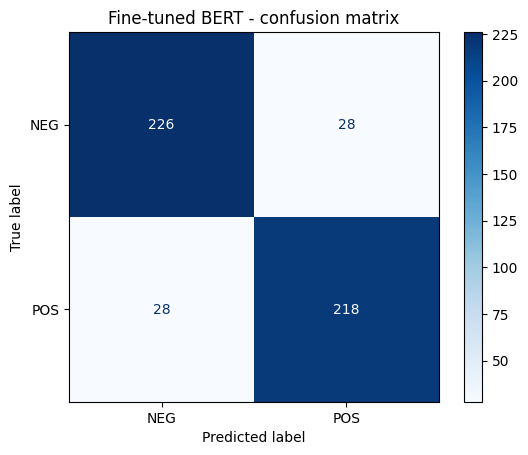

In [9]:
# Evaluation
out = trainer.predict(test_tok)
y_pred = np.argmax(out.predictions, axis=1)
print("Test metrics:", out.metrics)
print(classification_report(out.label_ids, y_pred, target_names=["NEGATIVE", "POSITIVE"]))
ConfusionMatrixDisplay.from_predictions(out.label_ids, y_pred, display_labels=["NEG", "POS"], cmap="Blues")
plt.title("Fine-tuned BERT - confusion matrix"); plt.show()

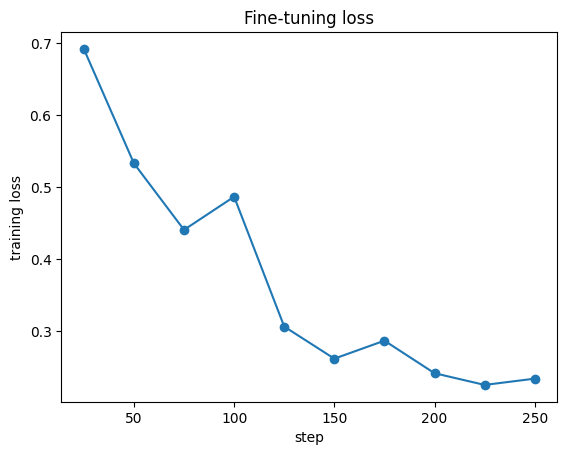

In [10]:
# Training loss curve
logs = [l for l in trainer.state.log_history if "loss" in l]
plt.plot([l["step"] for l in logs], [l["loss"] for l in logs], marker="o")
plt.xlabel("step"); plt.ylabel("training loss"); plt.title("Fine-tuning loss"); plt.show()

In [11]:
# Predict on new text
def predict(texts):
    enc = tokenizer(texts, truncation=True, padding=True, max_length=256, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = torch.softmax(model(**enc).logits, dim=-1).cpu().numpy()
    return probs

samples = ["An absolutely brilliant film with a touching story.",
           "Boring plot, terrible acting, I wanted to leave the theatre.",
           "It was okay, nothing special but not bad either."]
for s, p in zip(samples, predict(samples)):
    print(f"{model.config.id2label[int(p.argmax())]:8s} ({p.max():.2f}) <- {s}")

trainer.save_model("bert_imdb_final")
tokenizer.save_pretrained("bert_imdb_final")

POSITIVE (0.93) <- An absolutely brilliant film with a touching story.
NEGATIVE (0.96) <- Boring plot, terrible acting, I wanted to leave the theatre.
NEGATIVE (0.84) <- It was okay, nothing special but not bad either.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('bert_imdb_final/tokenizer_config.json', 'bert_imdb_final/tokenizer.json')